**ANOMALY DETECTION OC-SVM**

In [2]:
import digitalhub as dh
import zipfile
import json
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


In [3]:
job_names = ["net_v3_0per", "net_v3_20per", "net_v3_40per", "net_v3_60per", "net_v3_80per"]

def load_job(job_name):
    results_dir = f"/tmp/anomaly_results_cos_{job_name}"          
    shutil.rmtree(results_dir, ignore_errors=True)
    zip_path = project.get_artifact(f"anomaly_results_cos_{job_name}").download(f"{results_dir}.zip", overwrite=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(results_dir)
    with open(f"{results_dir}/anomaly_results.json") as f:
        results = json.load(f)
    df = pd.read_csv(f"{results_dir}/scores.csv")
    return results, df

summary = []        
all_rules = {}      

for job_name in job_names:
    results, df = load_job(job_name)
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    summary.append({
        "job_name": job_name,
        "min_flood_area": results["min_flood_area"],
        "thr_low": results['thr']['thr_low'], "thr_high": results['thr']['thr_high'],
        "n_fit": results["n_fit"], "n_normali": results["n_normali"], "n_anomale": results["n_anomale"],
        "score_normali": f"{score_normal.mean():.4f} ± {score_normal.std():.4f}",
        "score_anomale": f"{score_anom.mean():.4f} ± {score_anom.std():.4f}",
        "auroc_low": results["auroc_cos_sim_low_anom"],
        "auroc_high": results["auroc_cos_sim_high_anom"]
    })
    all_rules[job_name] = pd.DataFrame(results["rules"]).T

df_summary = pd.DataFrame(summary).set_index("job_name")
df_rules = pd.concat(all_rules, names=["job_name", "regola"])     

df_summary

,min_flood_area,thr_low,thr_high,n_fit,n_normali,n_anomale,score_normali,score_anomale,auroc_low,auroc_high
job_name,,,,,,,,,,
net_v3_0per,0.0,0.229413,0.491210,2572,2402,2402,0.3583 ± 0.1302,0.3388 ± 0.1460,0.537590,0.462410
net_v3_20per,20.0,0.229210,0.491437,2572,1085,1085,0.3525 ± 0.1292,0.3244 ± 0.1481,0.549561,0.450439
net_v3_40per,40.0,0.229210,0.491437,2572,642,642,0.3566 ± 0.1268,0.3157 ± 0.1436,0.570610,0.429390
net_v3_60per,60.0,0.229210,0.491437,2572,359,359,0.3552 ± 0.1271,0.3165 ± 0.1335,0.572466,0.427534
net_v3_80per,80.0,0.229210,0.491437,2572,173,173,0.3488 ± 0.1244,0.3178 ± 0.1347,0.554679,0.445321


In [4]:
df_rules

soglia     TP     FP      FN  \
job_name     regola                                                      
net_v3_0per  cos_sim > m+1*std          0.491210  367.0  367.0  2035.0   
             cos_sim < m-1*std          0.229413  571.0  373.0  1831.0   
             cos_sim fuori da m+-1*std       NaN  938.0  740.0  1464.0   
net_v3_20per cos_sim > m+1*std          0.491437  136.0  148.0   949.0   
             cos_sim < m-1*std          0.229210  294.0  162.0   791.0   
             cos_sim fuori da m+-1*std       NaN  430.0  310.0   655.0   
net_v3_40per cos_sim > m+1*std          0.491437   61.0   92.0   581.0   
             cos_sim < m-1*std          0.229210  175.0   91.0   467.0   
             cos_sim fuori da m+-1*std       NaN  236.0  183.0   406.0   
net_v3_60per cos_sim > m+1*std          0.491437   33.0   47.0   326.0   
             cos_sim < m-1*std          0.229210   93.0   50.0   266.0   
             cos_sim fuori da m+-1*std       NaN  126.0   97.0   233.0   
net_v3_80per cos_sim > m+1*std          0.491437   16.0   20.0   157.0   
             cos_sim < m-1*std          0.229210   43.0   25.0   130.0   
             cos_sim fuori da m+-1*std       NaN   59.0   45.0   114.0   

                                            TN   FA_rate   MA_rate       REC  \
job_name     regola                                                            
net_v3_0per  cos_sim > m+1*std          2035.0  0.152789  0.847211  0.152789   
             cos_sim < m-1*std          2029.0  0.155287  0.762281  0.237719   
             cos_sim fuori da m+-1*std  1662.0  0.308077  0.609492  0.390508   
net_v3_20per cos_sim > m+1*std           937.0  0.136406  0.874654  0.125346   
             cos_sim < m-1*std           923.0  0.149309  0.729032  0.270968   
             cos_sim fuori da m+-1*std   775.0  0.285714  0.603687  0.396313   
net_v3_40per cos_sim > m+1*std           550.0  0.143302  0.904984  0.095016   
             cos_sim < m-1*std           551.0  0.141745  0.727414  0.272586   
             cos_sim fuori da m+-1*std   459.0  0.285047  0.632399  0.367601   
net_v3_60per cos_sim > m+1*std           312.0  0.130919  0.908078  0.091922   
             cos_sim < m-1*std           309.0  0.139276  0.740947  0.259053   
             cos_sim fuori da m+-1*std   262.0  0.270195  0.649025  0.350975   
net_v3_80per cos_sim > m+1*std           153.0  0.115607  0.907514  0.092486   
             cos_sim < m-1*std           148.0  0.144509  0.751445  0.248555   
             cos_sim fuori da m+-1*std   128.0  0.260116  0.658960  0.341040   

                                            PREC        F1  soglia_low  \
job_name     regola                                                      
net_v3_0per  cos_sim > m+1*std          0.500000  0.234056         NaN   
             cos_sim < m-1*std          0.604873  0.341303         NaN   
             cos_sim fuori da m+-1*std  0.558999  0.459804    0.229413   
net_v3_20per cos_sim > m+1*std          0.478873  0.198685         NaN   
             cos_sim < m-1*std          0.644737  0.381570         NaN   
             cos_sim fuori da m+-1*std  0.581081  0.471233    0.229210   
net_v3_40per cos_sim > m+1*std          0.398693  0.153459         NaN   
             cos_sim < m-1*std          0.657895  0.385463         NaN   
             cos_sim fuori da m+-1*std  0.563246  0.444863    0.229210   
net_v3_60per cos_sim > m+1*std          0.412500  0.150342         NaN   
             cos_sim < m-1*std          0.650350  0.370518         NaN   
             cos_sim fuori da m+-1*std  0.565022  0.432990    0.229210   
net_v3_80per cos_sim > m+1*std          0.444444  0.153110         NaN   
             cos_sim < m-1*std          0.632353  0.356846         NaN   
             cos_sim fuori da m+-1*std  0.567308  0.425993    0.229210   

                                        soglia_high  
job_name     regola                                  
net_v3_0per  cos_sim > m+1*std                  NaN  
 

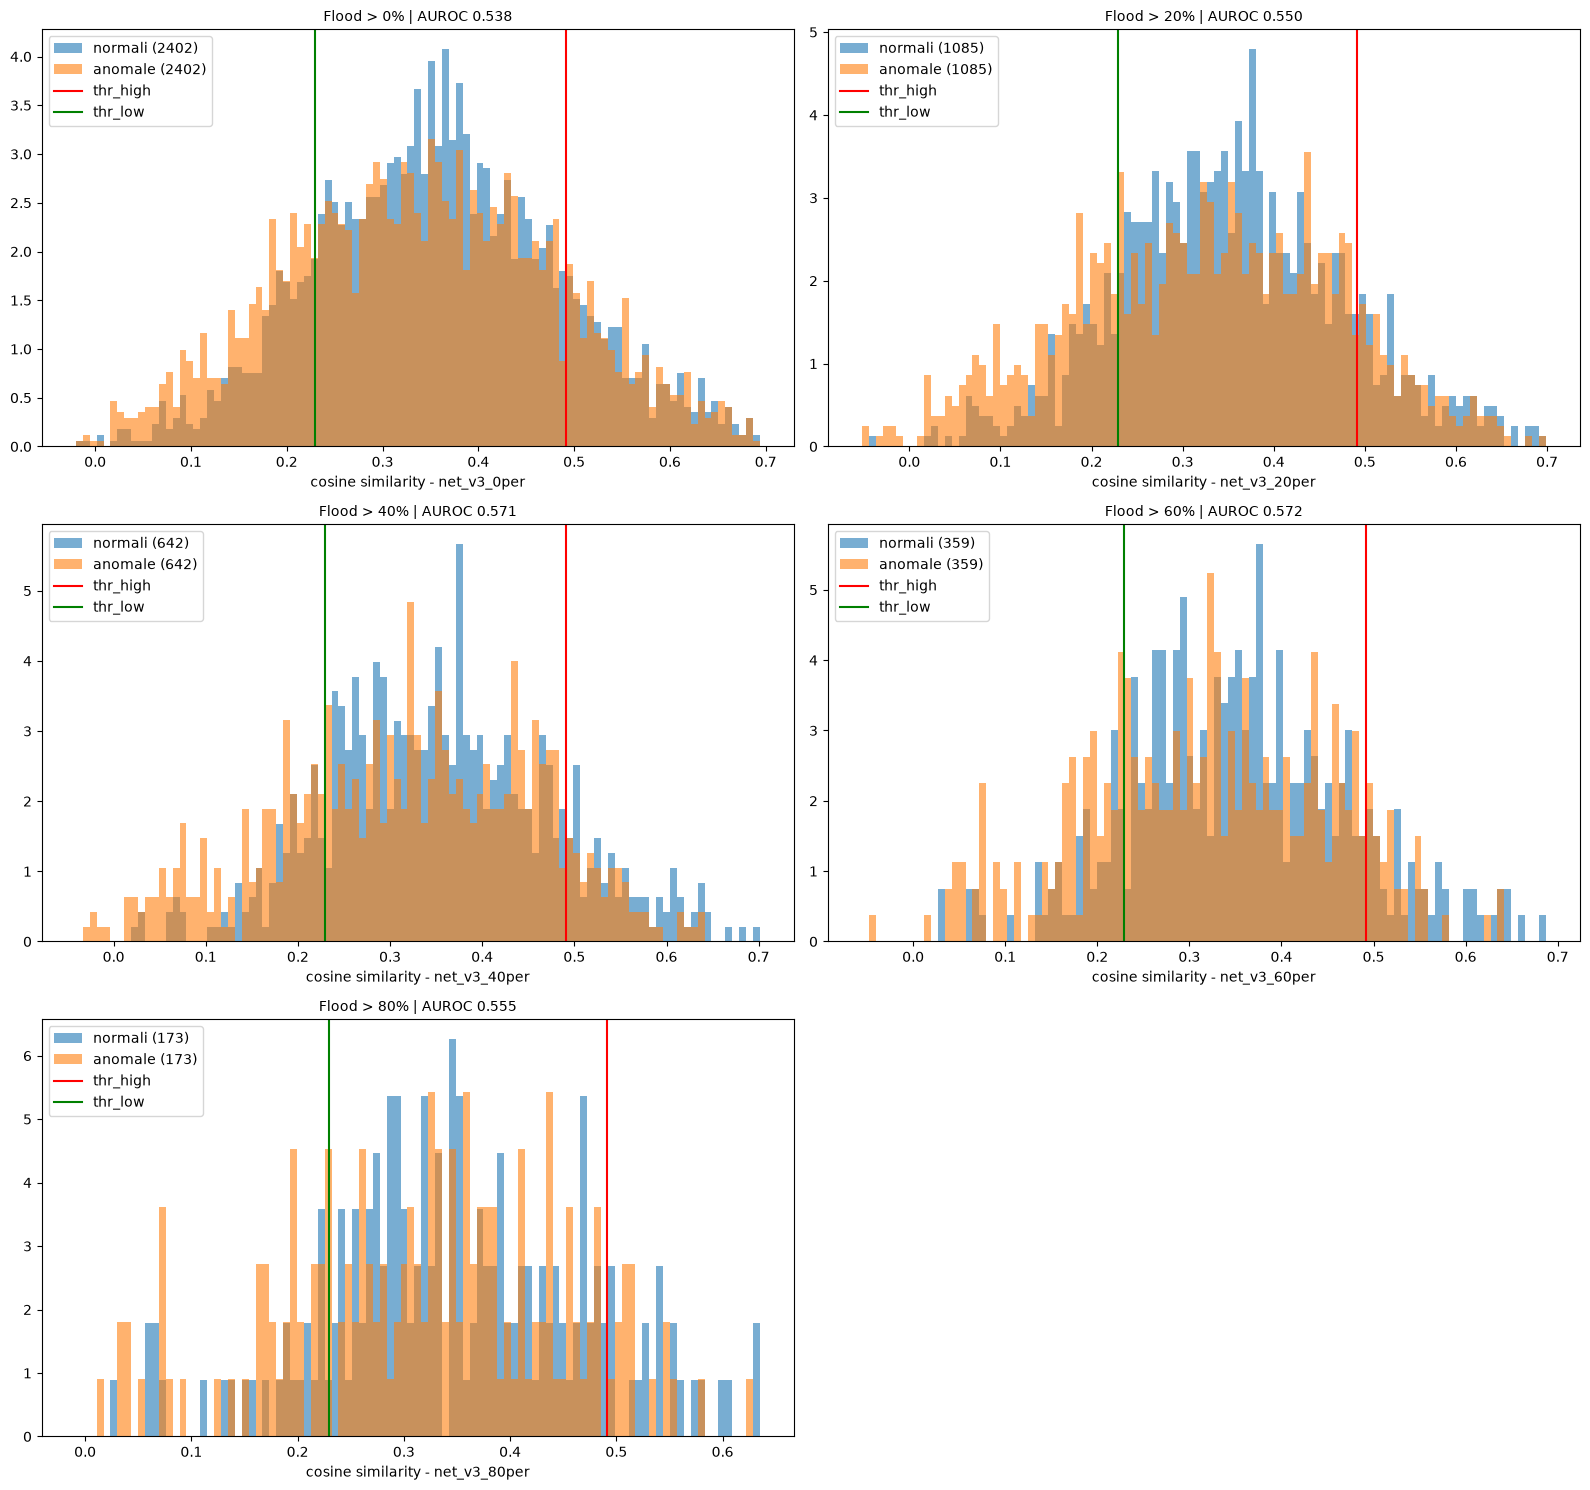

In [5]:
def plot_hist(ax, job_name, results, df):
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    lo, hi = np.quantile(df.score, [0.005, 0.995])              
    bins = np.linspace(lo, hi, 100)

    thr_high = results['thr']['thr_high']
    thr_low = results['thr']['thr_low']


    ax.hist(score_normal, bins=bins, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
    ax.hist(score_anom, bins=bins, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")
    ax.axvline(x=thr_high, color='r', label='thr_high')
    ax.axvline(x=thr_low, color='g', label='thr_low')
    ax.set_xlabel(f"cosine similarity - {job_name}")
    ax.legend(loc="upper left")
    ax.set_title(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc_cos_sim_low_anom']:.3f}", fontsize=10)


n_cols = 2
n_rows = int(np.ceil(len(job_names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(8 * n_cols, 5 * n_rows), squeeze=False)

for ax, job_name in zip(axes.flat, job_names):
    results, df = load_job(job_name)
    plot_hist(ax, job_name, results, df)

for ax in axes.flat[len(job_names):]:                           
    ax.axis("off")

plt.tight_layout()
plt.show()

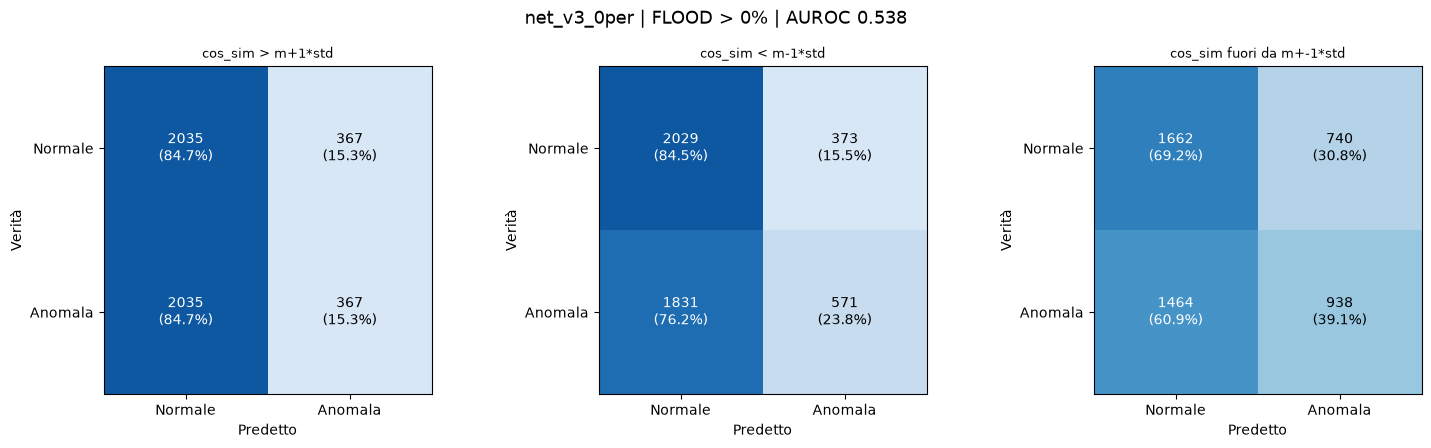

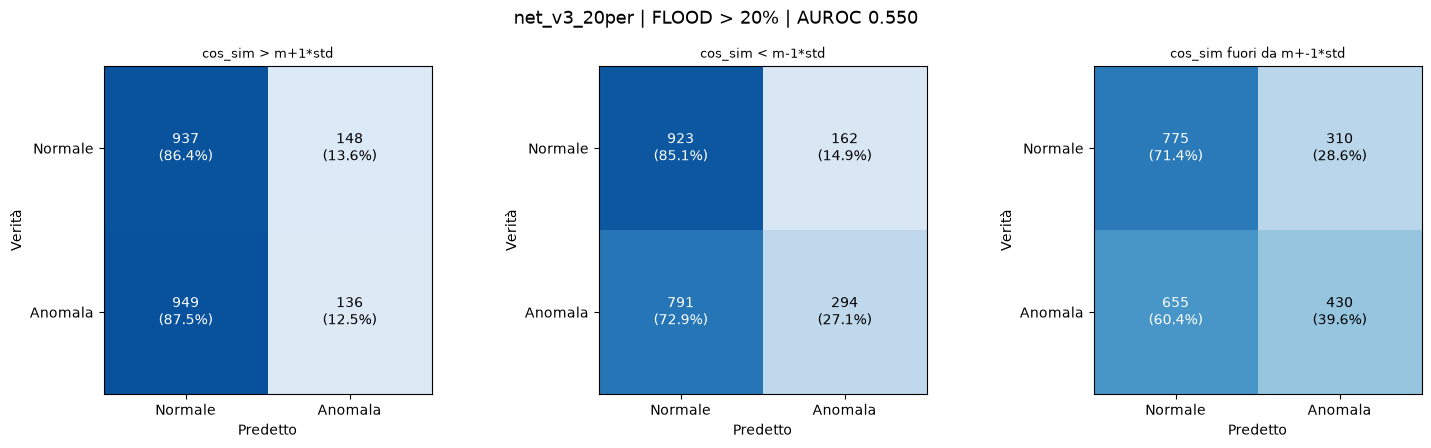

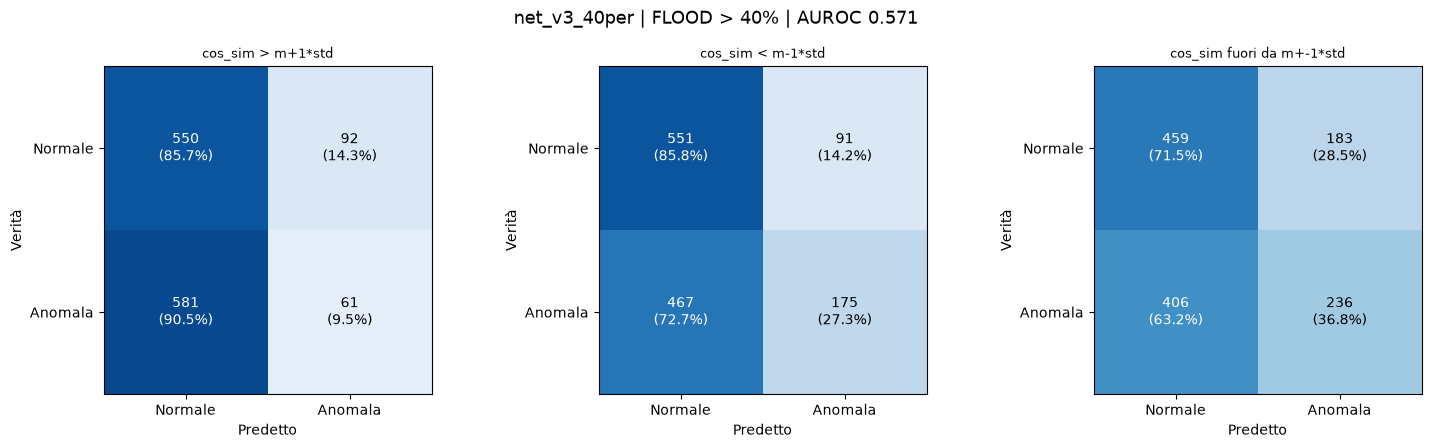

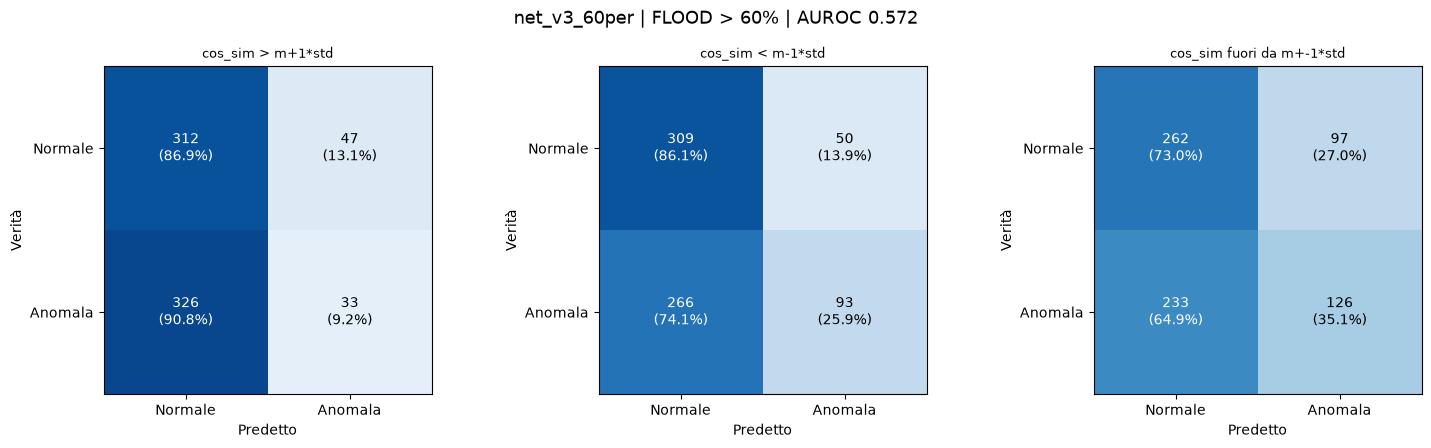

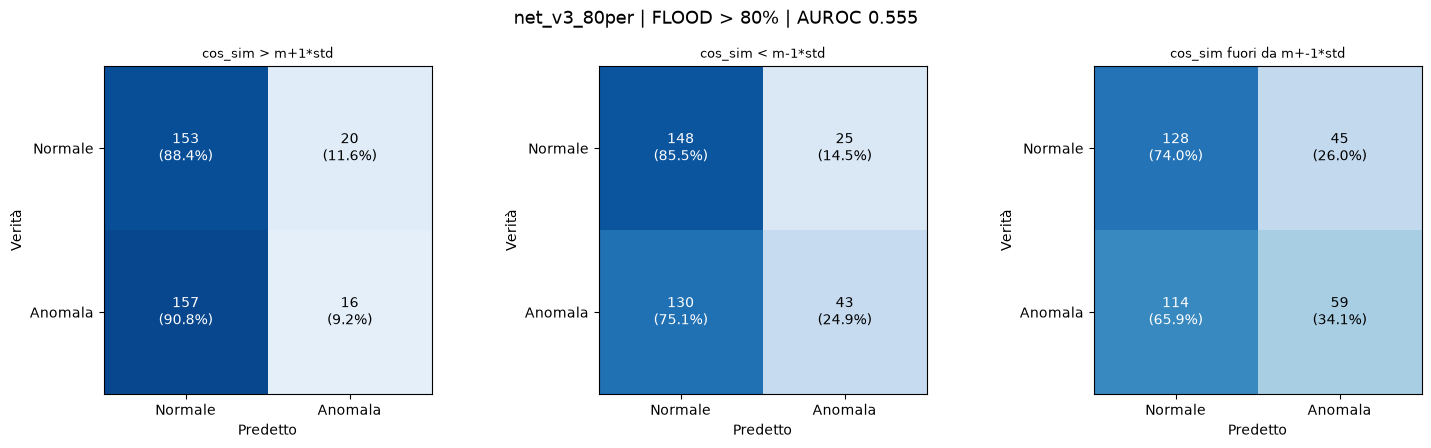

In [6]:
def plot_confusion(job_name, results):
    rules = results["rules"]
    fig, axes = plt.subplots(1, len(rules), figsize=(5 * len(rules), 4.5), squeeze=False)

    for ax, (nome, r) in zip(axes[0], rules.items()):
        mat = np.array([[r["TN"], r["FP"]],
                        [r["FN"], r["TP"]]])
        mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

        ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
        ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
        ax.set_title(nome, fontsize=9)

        for i in range(2):
            for j in range(2):
                color = "white" if mat_pct[i, j] > 55 else "black"
                ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                        ha="center", va="center", color=color, fontsize=10)

    fig.suptitle(f"{job_name} | FLOOD > {results['min_flood_area']:.0f}% | AUROC {results['auroc_cos_sim_low_anom']:.3f}", fontsize=13)
    plt.tight_layout()
    plt.show()


for job_name in job_names:
    results, df = load_job(job_name)
    plot_confusion(job_name, results)